# US National Debt vs. Party in Power

This notebook walks through the full process behind the
[national-debt chart](../national-debt/): load the raw Treasury debt
series and the party-in-power series, restrict both to a recent window,
derive the rate of change of the debt, and plot both shaded by which
party held the presidency.

It's the runnable, step-by-step version of `debt_viz.py` — the chart on
the website is a static/interactive JS build of the same logic; this
notebook is for seeing (and tweaking) the actual computation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Bold titles/labels for readability
rcParams.update({
    'axes.titlesize': 16,
    'axes.labelsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'font.weight': 'bold',
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
})

## Data paths and party colors

Two source files, both scraped/derived from Wikipedia + U.S. Treasury
data (see `data/scrape_wiki_electrion_winners.py`):

- `data/hst_debt.json` — historical total outstanding debt
- `data/us_party_in_power_by_year.json` — which party held the presidency
  for the majority of each year

In [2]:
DEBT_JSON_PATH = 'data/hst_debt.json'
PARTY_JSON_PATH = 'data/us_party_in_power_by_year.json'

PARTY_COLORS_DICT = {
    'Democratic': '#0015BC',
    'Republican': '#E9141D',
    'Democratic-Republican': '#6E6E6E',
    'Federalist': '#16E220',
    'Whig': '#F7941D',
    'Unaffiliated': '#000000',
    'National Union': '#8B4513',
    'Independent': '#A9A9A9',
    'No party': '#A9A9A9',
}

## Loading and cleaning

`parse_debt_json` flattens the nested Treasury JSON and coerces the
amount to a float; `check_df_for_nan` is a guard that fails loudly if
anything didn't parse.

In [3]:
def check_df_for_nan(df):
    """Raise if any column has NaN values."""
    nan_values = df.isna().sum()
    if nan_values.any():
        raise ValueError(f"NaN values found in the debt data:\n{nan_values}")


def parse_debt_json(debt_json):
    """Load + flatten the Treasury debt JSON into a tidy DataFrame."""
    debt_data = pd.read_json(debt_json)
    normalized_data = pd.json_normalize(debt_data['data'])
    normalized_data.sort_values(by='record_date', ascending=True, inplace=True)
    normalized_data['debt_outstanding_amt'] = pd.to_numeric(
        normalized_data['debt_outstanding_amt'], errors='raise'
    ).astype(float)
    check_df_for_nan(normalized_data)
    return normalized_data


def parse_party_json(party_json):
    """Load the party-in-power-by-year JSON into a tidy DataFrame."""
    party_data = pd.read_json(party_json)
    party_data.sort_values(by='record_date', ascending=True, inplace=True)
    return party_data

In [4]:
df_debt = parse_debt_json(DEBT_JSON_PATH)
df_prty = parse_party_json(PARTY_JSON_PATH)

df_debt.head()

/tmp/ipykernel_33417/1438592854.py:12: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  normalized_data.sort_values(by='record_date', ascending=True, inplace=True)
/tmp/ipykernel_33417/1438592854.py:23: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  party_data.sort_values(by='record_date', ascending=True, inplace=True)


,record_date,debt_outstanding_amt
237,1790-01-01,71060508.50
236,1791-01-01,75463476.52
235,1792-01-01,77227924.66
234,1793-01-01,80358634.04
233,1794-01-01,78427404.77


## Restricting to a recent window

Presidents take office the year *after* their election, so a plain
"last N years" cutoff can split a presidential term in half. This keeps
whole terms intact by rounding the cutoff back to the start of the most
recent term.

In [5]:
def restrict_n_years(df, n_years=100):
    """Keep the last n_years, extended back to the start of a term."""
    current_year = pd.Timestamp.now().year
    years_since_election = current_year % 4
    years_in_office = years_since_election - 1
    coverage = n_years + years_in_office
    search_year = current_year - coverage
    cutoff_year = search_year - 1

    df = df.copy()
    df['record_date'] = pd.to_datetime(df['record_date'])
    return df[df['record_date'].dt.year >= cutoff_year]


N_YEARS = 50  # try changing this and re-running the plot cells below

df_debt = restrict_n_years(df_debt, n_years=N_YEARS)
df_prty = restrict_n_years(df_prty, n_years=N_YEARS)

## Units and the derivative

Convert to billions for readability, then take d(debt)/dt. Records
aren't perfectly evenly spaced (fiscal year-end dates shift slightly),
so the derivative uses the *actual* elapsed time between records via
`np.gradient` rather than assuming a fixed step.

In [6]:
def convert_to_billions(df):
    df = df.copy()
    df['debt_outstanding_amt'] = df['debt_outstanding_amt'] / 1e9
    return df


def add_debt_derivative(df):
    """d(debt)/dt in billions/year, against actual elapsed time."""
    years_elapsed = (df['record_date'] - df['record_date'].iloc[0]).dt.days / 365.25
    df = df.copy()
    df['debt_derivative'] = np.gradient(df['debt_outstanding_amt'], years_elapsed)
    return df


df_debt = convert_to_billions(df_debt)
df_debt = add_debt_derivative(df_debt)
df_debt.tail()

,record_date,debt_outstanding_amt,debt_derivative
4,2022-09-30,30928.911613,2370.830482
3,2023-09-30,33167.334045,2266.257879
2,2024-09-30,35464.673929,2233.419138
1,2025-09-30,37637.553495,2355.187624
0,2026-09-30,40171.825101,2536.007409


## Mapping party colors

Every party in the restricted window needs a color — this fails loudly
(instead of silently plotting blank bands) if a new party ever shows up
without one.

In [7]:
df_prty['party_color'] = df_prty['party'].map(PARTY_COLORS_DICT)
unmapped_parties = df_prty.loc[df_prty['party_color'].isna(), 'party'].unique()
if len(unmapped_parties):
    raise ValueError(f"No color defined for party/parties: {list(unmapped_parties)}")

df_prty['party'].value_counts()

party
Republican    29
Democratic    24
Name: count, dtype: int64

## Plot

Total debt and its derivative, side by side, each with a `axvspan` band
per year colored by the party in power that year.

findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.


findfont: Failed to find font weight bold for cmmi10, now using 400.


findfont: Failed to find font weight bold for cmsy10, now using 400.


findfont: Failed to find font weight bold for cmr10, now using 400.


findfont: Failed to find font weight bold for cmtt10, now using 400.


findfont: Failed to find font weight bold for cmti10, now using 400.


findfont: Failed to find font weight bold for cmb10, now using 400.


findfont: Failed to find font weight bold for cmss10, now using 400.


findfont: Failed to find font weight bold for cmex10, now using 400.


findfont: Failed to find font weight bold for DejaVu Sans Display, now using 400.


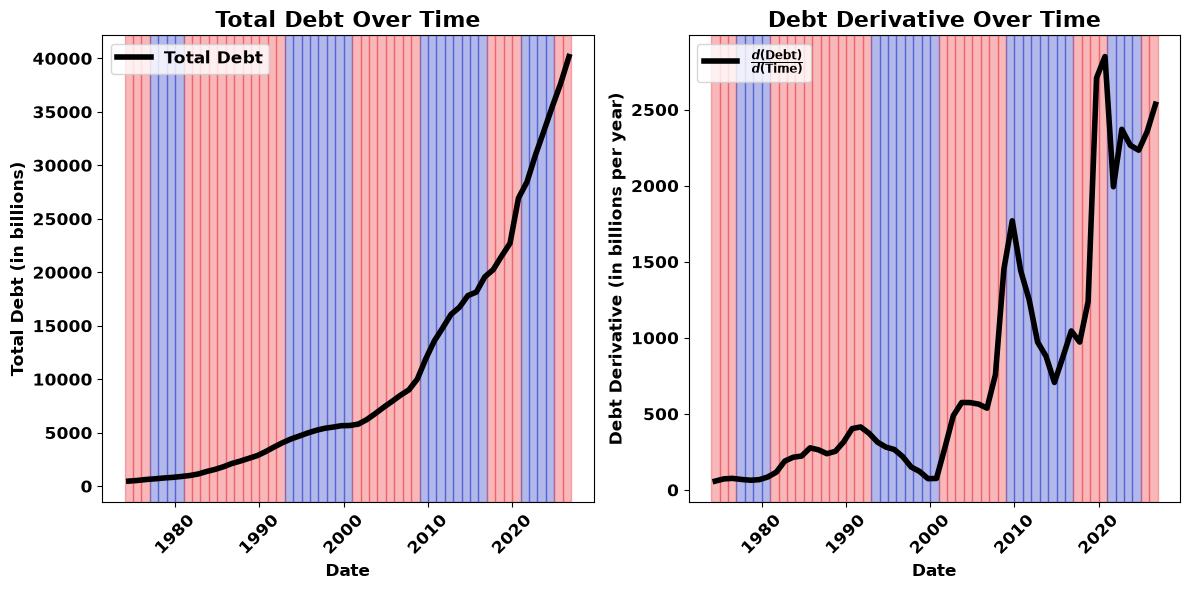

In [8]:
import matplotlib.dates as mdates

_, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].plot(df_debt['record_date'], df_debt['debt_outstanding_amt'],
           label='Total Debt', color='black', linewidth=4)
for _, row in df_prty.iterrows():
    start_date = row['record_date']
    end_date = start_date + pd.DateOffset(years=1)
    ax[0].axvspan(start_date, end_date, color=row['party_color'], alpha=0.3)
ax[0].set_title('Total Debt Over Time')
ax[0].set_xlabel('Date')
ax[0].set_ylabel('Total Debt (in billions)')
ax[0].legend()
ax[0].tick_params(axis='x', rotation=45)

# Black where non-negative, cyan where negative. Each zero crossing gets its
# own interpolated point so the color changes exactly at y = 0.
dates = mdates.date2num(df_debt['record_date'])
deriv = df_debt['debt_derivative'].to_numpy()
i = np.where(deriv[:-1] * deriv[1:] < 0)[0]
crossings = dates[i] - deriv[i] * (dates[i + 1] - dates[i]) / (deriv[i + 1] - deriv[i])
dates = mdates.num2date(np.insert(dates, i + 1, crossings))
deriv = np.insert(deriv, i + 1, 0.0)

ax[1].plot(dates, np.where(deriv >= 0, deriv, np.nan),
           label=r'$\frac{d(\mathrm{Debt})}{d(\mathrm{Time})}$',
           color='black', linewidth=4)
if (deriv < 0).any():
    ax[1].plot(dates, np.where(deriv <= 0, deriv, np.nan),
               label=r'$\frac{d(\mathrm{Debt})}{d(\mathrm{Time})} < 0$',
               color='cyan', linewidth=4)
for _, row in df_prty.iterrows():
    start_date = row['record_date']
    end_date = start_date + pd.DateOffset(years=1)
    ax[1].axvspan(start_date, end_date, color=row['party_color'], alpha=0.3)
ax[1].set_title('Debt Derivative Over Time')
ax[1].set_xlabel('Date')
ax[1].set_ylabel('Debt Derivative (in billions per year)')
ax[1].legend()
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()